# STEAD Samples Figure

## Moe Predict

In [1]:
# trace_name='GDXB.NC_20150501225411_EV'#GDXB.NC_20150501225411_EV_M0.56_SNR_22.5
# trace_name='GO02.C_20130925131520_EV'# GO02.C_20130925131520_EV_M5.3_SNR_71
# trace_name='M02C.TA_20131011230555_EV'# M02C.TA_20131011230555_EV_M5.2_SNR_75
# trace_name='B004.PB_20140905132114_EV'# B004.PB_20140905132114_EV_M0.42_SNR_7.1
# trace_name='B013.PB_20110710113727_EV'# B013.PB_20110710113727_EV_M0.4_SNR_8.2

In [2]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def Moe_predict(trace_name):
        import sys
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        # 将自定义模型文件所在目录加入路径
        sys.path.append("/home/yuan/code/SeisMoE/src")
        # 导入自定义模型文件，假设其中包含与 seisbench EQTransformer 接口相同的模型类
        from model_moe_gpt_PS2_CPU import IMG1

        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测"""
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            best_p = p_peaks[p_props['peak_heights'].argmax()] if len(p_peaks) > 0 else None
            best_s = None

            if best_p is not None:
                for s in s_peaks:
                    if 0 < (s - best_p) < 6000:  # 60秒窗口(100Hz采样)
                        best_s = s
                        break

            return best_p, best_s, p_props['peak_heights'].max() if best_p is not None else None, \
                   s_props['peak_heights'][s_peaks.tolist().index(best_s)] if best_s is not None else None



        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)




        hdf5_path="/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
        p_thresh=0.1,
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized.T).unsqueeze(0)


        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = IMG1().to(device)
        model.load_state_dict(torch.load("/home/yuan/code/SeisMoE/models/Model_Store/CPU2_moe_expert16/best_model.pth",map_location=device))

        model.eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output,_ = model_predict(model, data)
        moe_p_prob= output[0].cpu()
        moe_s_prob= output[1].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(moe_p_prob, moe_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))

        # output_csv = os.path.join(output_dir, 'picks——moe2.csv')
        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])

        moe_p=results['p_idx'].values[0]
        moe_s=results['s_idx'].values[0]
        moe_pc=results['p_conf'].values[0]
        moe_sc=results['s_conf'].values[0]


        print(f"Moe P index:{results['p_idx'].values[0]}")
        print(f"Moe S index:{results['s_idx'].values[0]}")
        print(f"Moe P confidence:{results['p_conf'].values[0]}")
        print(f"Moe S confidence:{results['s_conf'].values[0]}")

        return moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob





## Eqtransformer Predict

In [3]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def EQT_Predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name

        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.EQTransformer.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        eqt_p_prob= output[1].cpu()
        eqt_s_prob= output[2].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(eqt_p_prob, eqt_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        eqt_p=results['p_idx'].values[0]
        eqt_s=results['s_idx'].values[0]
        eqt_pc=results['p_conf'].values[0]
        eqt_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"eqt P index:{results['p_idx'].values[0]}")
        print(f"eqt S index:{results['s_idx'].values[0]}")
        print(f"eqt P confidence:{results['p_conf'].values[0]}")
        print(f"eqt S confidence:{results['s_conf'].values[0]}")

        return eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob


## PhaseNet Predict

In [4]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def PhaseNet_predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path="/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name

        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.PhaseNet.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        phasenet_p_prob= output[:, 1, :].cpu()
        phasenet_s_prob= output[:, 2, :].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(phasenet_p_prob, phasenet_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        phasenet_p=results['p_idx'].values[0]
        phasenet_s=results['s_idx'].values[0]
        phasenet_pc=results['p_conf'].values[0]
        phasenet_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"phasenet P index:{results['p_idx'].values[0]}")
        print(f"phasenet S index:{results['s_idx'].values[0]}")
        print(f"phasenet P confidence:{results['p_conf'].values[0]}")
        print(f"phasenet S confidence:{results['s_conf'].values[0]}")

        return phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob


##  signal figure

In [15]:
# from scipy.signal import resample, butter, filtfilt
# import pandas as pd
# import numpy as np
# def Example_Figure(trace_name,
#                    moe_p, moe_s, moe_pc, moe_sc, moe_p_prob, moe_s_prob,
#                    eqt_p, eqt_s, eqt_pc, eqt_sc, eqt_p_prob, eqt_s_prob,
#                    phasenet_p, phasenet_s, phasenet_pc, phasenet_sc, phasenet_p_prob, phasenet_s_prob,
#                    Pquen1=50,
#                    Pquen2=50,
#                    Squen1=100,
#                    Squen2=100,
#                    store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
#                    store_name='trace_name'):
#     cs = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.csv"
#     csv_data = pd.read_csv(cs)
#     Psample = int(csv_data[csv_data['trace_name'] == trace_name]['p_arrival_sample'].values[0])
#     Ssample = int(csv_data[csv_data['trace_name'] == trace_name]['s_arrival_sample'].values[0])
#     print(f"Psample:{Psample}")
#     print(f"Ssample:{Ssample}")

#     import scienceplots
#     import matplotlib.pyplot as plt
#     from mpl_toolkits.axes_grid1.inset_locator import inset_axes
#     from matplotlib.patches import ConnectionPatch
#     import matplotlib.gridspec as gridspec
#     import h5py
#     import os

#     # base_fontsize = 24
#     base_fontsize = 18
#     plt.rcParams.update({
#         'font.family': 'Times New Roman',
#         'font.size': base_fontsize,
#         'axes.labelsize': base_fontsize * 0.8,
#         'axes.titlesize': base_fontsize * 1.0,
#         'xtick.labelsize': base_fontsize * 0.7,
#         'ytick.labelsize': base_fontsize * 0.7,
#         'legend.fontsize': base_fontsize * 0.7,
#         'figure.titlesize': base_fontsize * 1.0,
#     })

#     try:
#         phasenet_p_prob = np.squeeze(phasenet_p_prob.numpy())
#         phasenet_s_prob = np.squeeze(phasenet_s_prob.numpy())
#         eqt_p_prob = np.squeeze(eqt_p_prob.numpy())
#         eqt_s_prob = np.squeeze(eqt_s_prob.numpy())
#         moe_p_prob = np.squeeze(moe_p_prob.numpy())
#         moe_s_prob = np.squeeze(moe_s_prob.numpy())
#     except Exception:
#         pass

#     def normalize_data1(data, mode='max'):
#         data -= np.mean(data, axis=1, keepdims=True)
#         if mode == 'std':
#             std_val = np.std(data, axis=1, keepdims=True)
#             std_val[std_val == 0] = 1.0
#             data /= std_val
#         elif mode == 'max':
#             max_val = np.max(np.abs(data), axis=1, keepdims=True)
#             max_val[max_val == 0] = 1.0
#             data /= max_val
#         else:
#             raise ValueError(f"Unsupported norm_mode: {mode}")
#         return data

#     def bandpass_filter(data, lowcut, highcut, fs, order=4):
#         nyquist = 0.5 * fs
#         low = lowcut / nyquist
#         high = highcut / nyquist
#         b, a = butter(order, [low, high], btype='band')
#         filtered = np.zeros_like(data)
#         for ch in range(data.shape[0]):
#             filtered[ch] = filtfilt(b, a, data[ch])
#         return filtered

#     hd = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
#     ID = trace_name
#     with h5py.File(hd, 'r') as f1:
#         data = f1.get('data/' + str(ID))[:]

#     data = bandpass_filter(data.T, lowcut=1.0, highcut=45.0, fs=100)
#     data = normalize_data1(data, 'max').T

#     with plt.style.context(['science', 'ieee']):
#         # gs = gridspec.GridSpec(4, 1, height_ratios=[0.5, 0.5, 0.5, 0.5])
#         # fig = plt.figure(figsize=(16, 10))
#         gs = gridspec.GridSpec(4, 2, width_ratios=[4.2, 1.5],height_ratios=[1, 1, 1, 1],hspace=0.3,wspace=0.15)
#         fig = plt.figure(figsize=(7, 4))
#         # axs = [fig.add_subplot(gs[i, 0]) for i in range(4)]
#         # axins1 = [fig.add_subplot(gs[i, 1]) for i in range(4)]

#         # 左侧4个主图
#         axs = [
#             fig.add_subplot(gs[0, 0]),
#             fig.add_subplot(gs[1, 0]),
#             fig.add_subplot(gs[2, 0]),
#             fig.add_subplot(gs[3, 0])
#         ]

#         # 右侧4个放大图
#         axins1 = fig.add_subplot(gs[0, 1])   # P波波形
#         axins2 = fig.add_subplot(gs[1, 1])   # S波波形
#         axins3 = fig.add_subplot(gs[2, 1])   # P波概率
#         axins4 = fig.add_subplot(gs[3, 1])   # S波概率

#         axs[0].plot(data[:, 2], color='k', linewidth=0.35)

#         axs[0].axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
#         axs[0].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
#         axs[0].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
#         axs[0].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
#         axs[0].axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[0].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[0].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)
#         axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)

#         axs[0].set_ylabel('Amplitude')
#         axs[0].set_ylim(-1, 1)
#         axs[0].set_xlim(0, 6000)
#         axs[0].set_xticks([])

#         # pos = axs[0].get_position()
#         # axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#         #                     bbox_to_anchor=(pos.x0, 0.83, 0.3, 0.3),
#         #                     bbox_transform=fig.transFigure)
#         axins1.plot(data[:, 2], color='k', linewidth=1)
#         # x_position = max(0, int(Psample - Pquen1))
#         # y_position = min(data.shape[0], int(Psample + Pquen2))
#         x_position=Psample-Pquen1
#         # y_position=Psample+Pquen2
#         y_position=Psample+Pquen2+00

#         axins1.set_xlim(x_position, y_position)
#         axins1.set_ylim(-1, 1)
#         axins1.axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
#         axins1.axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
#         axins1.axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
#         axins1.axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)

#         # axins1.set_title('P', fontsize=8, pad=2)

#         axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), y_position - x_position, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
#                                        fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
#         # con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA='data', coordsB='data',
#         #                        axesA=axs[0], axesB=axins1, color='k', linestyle='--', linewidth=0.5)
#         # con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA='data', coordsB='data',
#         #                        axesA=axs[0], axesB=axins1, color='k', linestyle='--', linewidth=0.5)
#         # axs[0].add_artist(con1)
#         # axs[0].add_artist(con2)

#         # axins1.xaxis.tick_top()
#         # axins1.xaxis.set_label_position('top')

#         # axins2 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#         #                     bbox_to_anchor=(pos.x1 - 0.3, 0.83, 0.3, 0.3),
#         #                     bbox_transform=fig.transFigure)
#         axins2.plot(data[:, 2], color='k', linewidth=1)

#         # x_position = max(0, int(Ssample - Squen1))
#         # y_position = min(data.shape[0], int(Ssample + Squen2))
#         x_position=Ssample-Squen1-20
#         y_position=Ssample+Squen2+50

#         axins2.set_xlim(x_position, y_position)
#         axins2.axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
#         axins2.axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
#         axins2.axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
#         axins2.axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)

#         # axins2.set_title('S', fontsize=8, pad=2)

#         axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), y_position - x_position, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
#                                        fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
#         # con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA='data', coordsB='data',
#         #                        axesA=axs[0], axesB=axins2, color='k', linestyle='--', linewidth=0.5)
#         # con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA='data', coordsB='data',
#         #                        axesA=axs[0], axesB=axins2, color='k', linestyle='--', linewidth=0.5)
#         # axs[0].add_artist(con3)
#         # axs[0].add_artist(con4)

#         # axins2.xaxis.tick_top()
#         # axins2.xaxis.set_label_position('top')

#         axs[1].plot(data[:, 1], color='k', linewidth=0.35)
#         axs[1].axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
#         axs[1].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
#         axs[1].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
#         axs[1].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
#         axs[1].axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[1].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[1].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)
#         axs[1].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)

#         axs[1].set_ylabel('Amplitude')
#         axs[1].set_xlim(0, 6000)
#         axs[1].set_ylim(-1, 1)
#         axs[1].set_xticks([])

#         axs[2].plot(data[:, 0], color='k', label='Z/E/N', linewidth=0.35)
#         axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='Lable', linewidth=1)
#         axs[2].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
#         axs[2].axvline(x=phasenet_p, color='#F3C846', linestyle='--', label='PhaseNet', linewidth=1)
#         axs[2].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
#         axs[2].axvline(x=eqt_p, color='#53ABD8', linestyle='--', label='EQTransformer', linewidth=1)
#         axs[2].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[2].axvline(x=moe_p, color='#8A233F', linestyle='--', label='SeisMoE', linewidth=1)
#         axs[2].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)
#         # axs[2].legend(loc='lower right', frameon=True)
#         axs[2].set_ylabel('Amplitude')
#         axs[2].set_xlim(0, 6000)
#         axs[2].set_ylim(-1, 1)
#         axs[2].set_xticks([])

#         axs[3].plot(phasenet_p_prob, color='#F3C846', linestyle='--', linewidth=1)
#         axs[3].plot(phasenet_s_prob, color='#F3C846', linestyle='--', linewidth=1)
#         axs[3].fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
#         axs[3].fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)

#         axs[3].plot(eqt_p_prob, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[3].plot(eqt_s_prob, color='#53ABD8', linestyle='--', linewidth=1)
#         axs[3].fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)
#         axs[3].fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)

#         axs[3].plot(moe_p_prob, color='#8A233F', linestyle='--', linewidth=1)
#         axs[3].plot(moe_s_prob, color='#8A233F', linestyle='--', linewidth=1)
#         axs[3].fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
#         axs[3].fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)

#         axs[3].set_ylim(0, 1)
#         axs[3].set_ylabel('Probability')
#         axs[3].set_xlabel('Sample', loc='right')
#         # axs[3].legend(loc='upper left', frameon=True)
#         axs[3].set_xlim(0, 6000)

#         handles, labels = axs[2].get_legend_handles_labels()

#         # 放在 axs[3] 的右侧（整张图的右下角）
#         # fig.legend(handles, labels, 
#         #         loc='lower left',           # 图例左下角对齐锚点
#         #         bbox_to_anchor=(axs[3].get_position().x1 -0.18,  
#         #                         axs[3].get_position().y0+0.04),        
#         #         frameon=True)

#         # pos = axs[3].get_position()
#         # axins3 = inset_axes(axs[3], width='100%', height='40%', loc='lower left',
#         #                     bbox_to_anchor=(pos.x0, -0.12, 0.3, 0.3),
#         #                     bbox_transform=fig.transFigure)
        
#         axins3.plot(moe_p_prob, color='#8A233F', linestyle='--', linewidth=1)
#         axins3.fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
#         axins3.plot(phasenet_p_prob, color='#F3C846', linestyle='--', linewidth=1)
#         axins3.fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
#         axins3.plot(eqt_p_prob, color='#53ABD8', linestyle='--', linewidth=1)
#         axins3.fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)

#         # x_position = max(0, int(Psample - Pquen1 * 1.3))
#         # y_position = min(len(phasenet_p_prob), int(Psample + Pquen2 * 1.3))
#         # x_position=Psample-Pquen1*1.4
#         # y_position=Psample+Pquen2*1.4+100
#         x_position=Psample-Pquen1
#         y_position=Psample+Pquen2+00

#         axins3.set_xlim(x_position, y_position)
#         axins3.set_ylim(0, 1)

#         # axins3.set_title('P', fontsize=8, pad=2)

#         axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), y_position - x_position, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
#                                        fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
#         # con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA='data', coordsB='data',
#         #                        axesA=axs[3], axesB=axins3, color='k', linestyle='--', linewidth=0.5)
#         # con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA='data', coordsB='data',
#         #                        axesA=axs[3], axesB=axins3, color='k', linestyle='--', linewidth=0.5)
#         # axs[3].add_artist(con5)
#         # axs[3].add_artist(con6)

#         # axins4 = inset_axes(axs[3], width='100%', height='40%', loc='lower left',
#         #                     bbox_to_anchor=(pos.x1 - 0.3, -0.12, 0.3, 0.3),
#         #                     bbox_transform=fig.transFigure)
        
#         axins4.plot(moe_s_prob, color='#8A233F', linestyle='--', linewidth=1)
#         axins4.fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)
#         axins4.plot(phasenet_s_prob, color='#F3C846', linestyle='--', linewidth=1)
#         axins4.fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)
#         axins4.plot(eqt_s_prob, color='#53ABD8', linestyle='--', linewidth=1)
#         axins4.fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)
        
#         # x_position = max(0, int(Ssample - Squen1 * 1.4))
#         # y_position = min(len(phasenet_s_prob), int(Ssample + Squen2 * 1.4)+100)
#         x_position=Ssample-Squen1-20
#         y_position=Ssample+Squen2+50
#         axins4.set_xlim(x_position, y_position)
#         axins4.set_ylim(0, 1)

#         # axins4.set_title('S', fontsize=8, pad=2)
        
#         axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), y_position - x_position, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
#                                        fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
#         # con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA='data', coordsB='data',
#         #                        axesA=axs[3], axesB=axins4, color='k', linestyle='--', linewidth=0.5)
#         # con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA='data', coordsB='data',
#         #                        axesA=axs[3], axesB=axins4, color='k', linestyle='--', linewidth=0.5)
#         # axs[3].add_artist(con7)
#         # axs[3].add_artist(con8)

#         # ============================================================
#         # 主图图例
#         # ============================================================
#         handles, labels = axs[2].get_legend_handles_labels()

#         axs[3].legend(
#             handles,
#             labels,
#             loc='lower right',
#             bbox_to_anchor=(0.985, 0.01),
#             frameon=True,
#             fontsize=10
#         )

#         # 第一行：保留上边框，只去掉下边框
#         axs[0].spines['top'].set_visible(True)
#         axs[0].spines['bottom'].set_visible(False)

#         # 第二、三行：上下边框都去掉
#         for ax in axs[1:3]:
#             ax.spines['top'].set_visible(False)
#             ax.spines['bottom'].set_visible(False)
#         # for ax in axs[:-1]:
#         #     ax.spines['top'].set_visible(False)
#         #     ax.spines['bottom'].set_visible(False)
#         #     ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
#         axs[3].spines['top'].set_visible(False)
#         axs[3].xaxis.set_ticks_position('bottom')

#         # ============================================================
#         # 右侧放大图格式
#         # ============================================================
#         for ax in [axins1, axins2, axins3, axins4]:

#             ax.tick_params(
#                 axis='both',
#                 labelsize=10,
#                 direction='in'
#             )

#             ax.spines['top'].set_linewidth(0.5)
#             ax.spines['bottom'].set_linewidth(0.5)
#             ax.spines['left'].set_linewidth(0.5)
#             ax.spines['right'].set_linewidth(0.5)


#         # ============================================================
#         # 右侧放大图可以不显示y轴标签
#         # 避免图太拥挤
#         # ============================================================
#         axins1.set_ylabel('')
#         axins2.set_ylabel('')
#         axins3.set_ylabel('')
#         axins4.set_ylabel('')


#         # ============================================================
#         # 调整整个图的边界
#         # ============================================================
#         plt.subplots_adjust(
#             left=0.08,
#             right=0.98,
#             top=0.97,
#             bottom=0.12
#         )



#         path_svg = os.path.join(store_path, store_name) + '.svg'
#         path_pdf = os.path.join(store_path, store_name) + '.pdf'
#         plt.tight_layout()
#         plt.savefig(path_pdf, dpi=600)
#         plt.savefig(path_svg, dpi=600)
#         plt.show()
#         plt.close()

###11111111111111111111111111111111111111111111111111111111111111111111111##
# from scipy.signal import butter, filtfilt
# import pandas as pd
# import numpy as np
# import scienceplots
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# from matplotlib.lines import Line2D
# import h5py
# import os


# def Example_Figure(trace_name,
#                    moe_p, moe_s, moe_pc, moe_sc, moe_p_prob, moe_s_prob,
#                    eqt_p, eqt_s, eqt_pc, eqt_sc, eqt_p_prob, eqt_s_prob,
#                    phasenet_p, phasenet_s, phasenet_pc, phasenet_sc, phasenet_p_prob, phasenet_s_prob,
#                    Pquen1=50,
#                    Pquen2=50,
#                    Squen1=100,
#                    Squen2=100,
#                    store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
#                    store_name='trace_name'):

#     cs = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.csv"
#     csv_data = pd.read_csv(cs)
#     Psample = int(csv_data[csv_data['trace_name'] == trace_name]['p_arrival_sample'].values[0])
#     Ssample = int(csv_data[csv_data['trace_name'] == trace_name]['s_arrival_sample'].values[0])
#     print(f"Psample:{Psample}")
#     print(f"Ssample:{Ssample}")

#     base_fontsize = 18
#     plt.rcParams.update({
#         'font.family': 'Times New Roman',
#         'font.size': base_fontsize,
#         'axes.labelsize': base_fontsize * 0.8,
#         'axes.titlesize': base_fontsize * 1.0,
#         'xtick.labelsize': base_fontsize * 0.7,
#         'ytick.labelsize': base_fontsize * 0.7,
#         'legend.fontsize': base_fontsize * 0.7,
#         'figure.titlesize': base_fontsize * 1.0,
#     })

#     try:
#         phasenet_p_prob = np.squeeze(phasenet_p_prob.numpy())
#         phasenet_s_prob = np.squeeze(phasenet_s_prob.numpy())
#         eqt_p_prob = np.squeeze(eqt_p_prob.numpy())
#         eqt_s_prob = np.squeeze(eqt_s_prob.numpy())
#         moe_p_prob = np.squeeze(moe_p_prob.numpy())
#         moe_s_prob = np.squeeze(moe_s_prob.numpy())
#     except Exception:
#         pass

#     def normalize_data1(data, mode='max'):
#         data = data.copy()
#         data -= np.mean(data, axis=1, keepdims=True)
#         if mode == 'std':
#             std_val = np.std(data, axis=1, keepdims=True)
#             std_val[std_val == 0] = 1.0
#             data /= std_val
#         elif mode == 'max':
#             max_val = np.max(np.abs(data), axis=1, keepdims=True)
#             max_val[max_val == 0] = 1.0
#             data /= max_val
#         else:
#             raise ValueError(f"Unsupported norm_mode: {mode}")
#         return data

#     def bandpass_filter(data, lowcut, highcut, fs, order=4):
#         nyquist = 0.5 * fs
#         low = lowcut / nyquist
#         high = highcut / nyquist
#         b, a = butter(order, [low, high], btype='band')
#         filtered = np.zeros_like(data)
#         for ch in range(data.shape[0]):
#             filtered[ch] = filtfilt(b, a, data[ch])
#         return filtered

#     hd = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
#     with h5py.File(hd, 'r') as f1:
#         data = f1.get('data/' + str(trace_name))[:]

#     data = bandpass_filter(data.T, lowcut=1.0, highcut=45.0, fs=100)
#     data = normalize_data1(data, 'max').T

#     c_label = '#329845'
#     c_phasenet = '#F3C846'
#     c_eqt = '#53ABD8'
#     c_moe = '#8A233F'
#     c_pwin = '#DCEAF7'
#     c_swin = '#F9E1E1'

#     npts = data.shape[0]
#     P_start = max(0, Psample - Pquen1)
#     P_end = min(npts, Psample + Pquen2)
#     S_start = max(0, Ssample - Squen1 - 20)
#     S_end = min(npts, Ssample + Squen2 + 50)

#     with plt.style.context(['science', 'ieee']):
#         gs = gridspec.GridSpec(6, 2, height_ratios=[1, 1, 1, 0.08, 1.15, 0.95], width_ratios=[1, 1], hspace=0.08, wspace=0.18)
#         fig = plt.figure(figsize=(8.4, 5.9))

#         ax_z = fig.add_subplot(gs[0, :])
#         ax_e = fig.add_subplot(gs[1, :], sharex=ax_z)
#         ax_n = fig.add_subplot(gs[2, :], sharex=ax_z)

#         # gs[3, :] 这一行空着，作为间距

#         ax_pw = fig.add_subplot(gs[4, 0])
#         ax_sw = fig.add_subplot(gs[4, 1])
#         ax_pp = fig.add_subplot(gs[5, 0], sharex=ax_pw)
#         ax_sp = fig.add_subplot(gs[5, 1], sharex=ax_sw)
#         # =========================
#         # 上半部分：Z
#         # =========================
#         ax_z.plot(data[:, 2], color='k', linewidth=0.35)
#         ax_z.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
#         ax_z.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)
#         ax_z.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
#         ax_z.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_z.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
#         ax_z.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
#         ax_z.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
#         ax_z.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_z.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
#         ax_z.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
#         ax_z.set_ylabel('Amp.')
#         ax_z.set_ylim(-1, 1)
#         ax_z.set_xlim(0, npts)
#         ax_z.text(0.01, 0.82, 'Z', transform=ax_z.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')
#         ax_z.xaxis.set_ticks_position('top')
#         ax_z.xaxis.set_label_position('top')
#         ax_z.tick_params(axis='x', which='both', top=True, bottom=False, labeltop=True, labelbottom=False)
#         ax_z.set_xlabel('Sample', loc='center', labelpad=5)

#         # =========================
#         # 上半部分：E
#         # =========================
#         ax_e.plot(data[:, 1], color='k', linewidth=0.35)
#         ax_e.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
#         ax_e.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)
#         ax_e.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
#         ax_e.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_e.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
#         ax_e.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
#         ax_e.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
#         ax_e.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_e.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
#         ax_e.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
#         ax_e.set_ylabel('Amp.')
#         ax_e.set_ylim(-1, 1)
#         ax_e.set_xlim(0, npts)
#         ax_e.text(0.01, 0.82, 'E', transform=ax_e.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')
#         ax_e.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False, labeltop=False)

#         # =========================
#         # 上半部分：N
#         # =========================
#         ax_n.plot(data[:, 0], color='k', linewidth=0.35)
#         ax_n.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
#         ax_n.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)
#         ax_n.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
#         ax_n.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_n.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
#         ax_n.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
#         ax_n.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
#         ax_n.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_n.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
#         ax_n.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
#         ax_n.set_ylabel('Amp.')
#         ax_n.set_ylim(-1, 1)
#         ax_n.set_xlim(0, npts)
#         ax_n.text(0.01, 0.82, 'N', transform=ax_n.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')
#         ax_n.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False, labeltop=False)

#         # 上半部分边框控制
#         ax_z.spines['top'].set_visible(True)
#         ax_z.spines['bottom'].set_visible(False)
#         ax_e.spines['top'].set_visible(False)
#         ax_e.spines['bottom'].set_visible(False)
#         ax_n.spines['top'].set_visible(False)
#         ax_n.spines['bottom'].set_visible(True)

#         # =========================
#         # 下半部分：P 局部波形
#         # =========================
#         p_x = np.arange(P_start, P_end)
#         ax_pw.plot(p_x, data[P_start:P_end, 2] + 1.8, color='k',linestyle='-', linewidth=0.5)
#         ax_pw.plot(p_x, data[P_start:P_end, 1] + 0.0, color='k',linestyle='-', linewidth=0.5)
#         ax_pw.plot(p_x, data[P_start:P_end, 0] - 1.8, color='k',linestyle='-', linewidth=0.5)
#         ax_pw.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
#         ax_pw.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_pw.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
#         ax_pw.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
#         ax_pw.set_xlim(P_start, P_end)
#         ax_pw.set_ylim(-2.5, 2.5)
#         ax_pw.set_yticks([1.8, 0.0, -1.8])
#         ax_pw.set_yticklabels(['Z', 'E', 'N'], fontsize=base_fontsize * 0.7)
#         ax_pw.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)

#         # =========================
#         # 下半部分：S 局部波形
#         # =========================
#         s_x = np.arange(S_start, S_end)
#         ax_sw.plot(s_x, data[S_start:S_end, 2] + 1.8, color='k', linestyle='-', linewidth=0.5)
#         ax_sw.plot(s_x, data[S_start:S_end, 1] + 0.0, color='k', linestyle='-', linewidth=0.5)
#         ax_sw.plot(s_x, data[S_start:S_end, 0] - 1.8, color='k', linestyle='-', linewidth=0.5)
#         ax_sw.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
#         ax_sw.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_sw.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
#         ax_sw.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
#         ax_sw.set_xlim(S_start, S_end)
#         ax_sw.set_ylim(-2.5, 2.5)
#         ax_sw.set_yticks([1.8, 0.0, -1.8])
#         ax_sw.set_yticklabels(['Z', 'E', 'N'], fontsize=base_fontsize * 0.7)
#         ax_sw.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)

#         # =========================
#         # 下半部分：P 概率
#         # =========================
#         ax_pp.plot(phasenet_p_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
#         ax_pp.plot(eqt_p_prob, color=c_eqt, linestyle='--', linewidth=1.2)
#         ax_pp.plot(moe_p_prob, color=c_moe, linestyle='--', linewidth=1.2)
#         ax_pp.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_pp.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
#         ax_pp.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
#         ax_pp.set_xlim(P_start, P_end)
#         ax_pp.set_ylim(0, 1)
#         ax_pp.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
#         ax_pp.set_xlabel('Sample', loc='center', fontsize=base_fontsize * 0.8)
#         ax_pp.set_ylabel('Prob.', fontsize=base_fontsize * 0.8)

#         # =========================
#         # 下半部分：S 概率
#         # =========================
#         ax_sp.plot(phasenet_s_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
#         ax_sp.plot(eqt_s_prob, color=c_eqt, linestyle='--', linewidth=1.2)
#         ax_sp.plot(moe_s_prob, color=c_moe, linestyle='--', linewidth=1.2)
#         ax_sp.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
#         ax_sp.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
#         ax_sp.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
#         ax_sp.set_xlim(S_start, S_end)
#         ax_sp.set_ylim(0, 1)
#         ax_sp.set_ylabel('Prob.', fontsize=base_fontsize * 0.8)
#         ax_sp.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
#         ax_sp.set_xlabel('Sample', loc='center', fontsize=base_fontsize * 0.8)

#         # 下半部分四个小图全部封边
#         for ax in [ax_pw, ax_sw, ax_pp, ax_sp]:
#             ax.spines['top'].set_visible(True)
#             ax.spines['bottom'].set_visible(True)
#             ax.spines['left'].set_visible(True)
#             ax.spines['right'].set_visible(True)
#             ax.tick_params(axis='both', labelsize=base_fontsize * 0.7, direction='in')

#         # 图例放在上半部分空白区域
#         handles = [
#             Line2D([], [], color='k', linewidth=1, label='Z/E/N'),
#             Line2D([], [], color=c_label, linestyle='--', linewidth=1, label='Label'),
#             Line2D([], [], color=c_phasenet, linestyle='--', linewidth=1, label='PhaseNet'),
#             Line2D([], [], color=c_eqt, linestyle='--', linewidth=1, label='EQTransformer'),
#             Line2D([], [], color=c_moe, linestyle='--', linewidth=1, label='SeisMoE')
#         ]
#         fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(0.78, 0.88), frameon=True, fontsize=9)

#         plt.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.10)

#         os.makedirs(store_path, exist_ok=True)
#         path_svg = os.path.join(store_path, store_name) + '.svg'
#         path_pdf = os.path.join(store_path, store_name) + '.pdf'
#         plt.savefig(path_pdf, dpi=600, bbox_inches='tight')
#         plt.savefig(path_svg, dpi=600, bbox_inches='tight')
#         plt.show()
#         plt.close()

##222222222222222222222222222222222222222222222222222222222222222222222222222222##
from scipy.signal import butter, filtfilt
import pandas as pd
import numpy as np
import scienceplots
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import h5py
import os


def Example_Figure(trace_name,
                   moe_p, moe_s, moe_pc, moe_sc, moe_p_prob, moe_s_prob,
                   eqt_p, eqt_s, eqt_pc, eqt_sc, eqt_p_prob, eqt_s_prob,
                   phasenet_p, phasenet_s, phasenet_pc, phasenet_sc, phasenet_p_prob, phasenet_s_prob,
                   Pquen1=50,
                   Pquen2=50,
                   Squen1=100,
                   Squen2=100,
                   store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
                   store_name='trace_name'):

    cs = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.csv"
    csv_data = pd.read_csv(cs)
    Psample = int(csv_data[csv_data['trace_name'] == trace_name]['p_arrival_sample'].values[0])
    Ssample = int(csv_data[csv_data['trace_name'] == trace_name]['s_arrival_sample'].values[0])

    print(f"Psample:{Psample}")
    print(f"Ssample:{Ssample}")

    base_fontsize = 22
    plt.rcParams.update({
        'font.family': 'Times New Roman',
        'font.size': base_fontsize,
        'axes.labelsize': base_fontsize * 0.8,
        'axes.titlesize': base_fontsize * 1.0,
        'xtick.labelsize': base_fontsize * 0.7,
        'ytick.labelsize': base_fontsize * 0.7,
        'legend.fontsize': base_fontsize * 0.7,
        'figure.titlesize': base_fontsize * 1.0,
    })

    try:
        phasenet_p_prob = np.squeeze(phasenet_p_prob.numpy())
        phasenet_s_prob = np.squeeze(phasenet_s_prob.numpy())
        eqt_p_prob = np.squeeze(eqt_p_prob.numpy())
        eqt_s_prob = np.squeeze(eqt_s_prob.numpy())
        moe_p_prob = np.squeeze(moe_p_prob.numpy())
        moe_s_prob = np.squeeze(moe_s_prob.numpy())
    except Exception:
        pass

    def normalize_data1(data, mode='max'):
        data = data.copy()
        data -= np.mean(data, axis=1, keepdims=True)
        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')
        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered

    hd = r"/mnt/d/AI_Seismic_Data/STEAD/STEAD.hdf5"
    with h5py.File(hd, 'r') as f1:
        data = f1.get('data/' + str(trace_name))[:]

    data = bandpass_filter(data.T, lowcut=1.0, highcut=45.0, fs=100)
    data = normalize_data1(data, 'max').T

    c_label ='#8A233F'
    c_phasenet = '#2ca02c'
    c_eqt = '#ff7f0e'
    c_moe = '#1f77b4'
    c_pwin = "#A8CBE6"
    c_swin = '#F9E1E1'

    npts = data.shape[0]
    P_start = max(0, Psample - Pquen1)
    P_end = min(npts, Psample + Pquen2+50)
    S_start = max(0, Ssample - Squen1 - 20)
    S_end = min(npts, Ssample + Squen2 + 50)

    with plt.style.context(['science', 'ieee']):

        gs = gridspec.GridSpec(4, 3, height_ratios=[1, 1, 1, 0.9], width_ratios=[2.2, 1, 1], hspace=0.18, wspace=0.18)
        fig = plt.figure(figsize=(10.5, 5.9))

        # ============================================================
        # 左列：完整波形
        # ============================================================
        ax_z = fig.add_subplot(gs[0, 0])
        ax_e = fig.add_subplot(gs[1, 0], sharex=ax_z)
        ax_n = fig.add_subplot(gs[2, 0], sharex=ax_z)
        ax_full_prob = fig.add_subplot(gs[3, 0], sharex=ax_z)

        # ============================================================
        # 中列：P局部
        # ============================================================
        ax_p_z = fig.add_subplot(gs[0, 1])
        ax_p_e = fig.add_subplot(gs[1, 1], sharex=ax_p_z)
        ax_p_n = fig.add_subplot(gs[2, 1], sharex=ax_p_z)
        ax_p_prob = fig.add_subplot(gs[3, 1], sharex=ax_p_z)

        # ============================================================
        # 右列：S局部
        # ============================================================
        ax_s_z = fig.add_subplot(gs[0, 2])
        ax_s_e = fig.add_subplot(gs[1, 2], sharex=ax_s_z)
        ax_s_n = fig.add_subplot(gs[2, 2], sharex=ax_s_z)
        ax_s_prob = fig.add_subplot(gs[3, 2], sharex=ax_s_z)

        # ============================================================
        # Full Z
        # ============================================================
        title_y = 1.04
        title_fs = base_fontsize * 0.8

        ax_z.plot(data[:, 2], color='k', linestyle='-', linewidth=0.35)
        ax_z.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
        ax_z.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)

        ax_z.text((P_start + P_end) / 2, title_y, 'P', transform=ax_z.get_xaxis_transform(), ha='center', va='bottom', fontsize=title_fs, clip_on=False)
        ax_z.text((S_start + S_end) / 2, title_y, 'S', transform=ax_z.get_xaxis_transform(), ha='center', va='bottom', fontsize=title_fs, clip_on=False)


        ax_z.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_z.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_z.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_z.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)

        ax_z.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_z.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_z.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_z.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)

        ax_z.set_xlim(0, npts)
        ax_z.set_ylim(-1, 1)
        ax_z.set_ylabel('Amp.')
        ax_z.text(0.01, 0.82, 'Z', transform=ax_z.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')

        # ============================================================
        # Full E
        # ============================================================
        ax_e.plot(data[:, 1], color='k', linestyle='-', linewidth=0.35)
        ax_e.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
        ax_e.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)

        ax_e.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_e.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_e.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_e.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)

        ax_e.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_e.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_e.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_e.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)

        ax_e.set_xlim(0, npts)
        ax_e.set_ylim(-1, 1)
        ax_e.set_ylabel('Amp.')
        ax_e.text(0.01, 0.82, 'E', transform=ax_e.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')

        # ============================================================
        # Full N
        # ============================================================
        ax_n.plot(data[:, 0], color='k', linestyle='-', linewidth=0.35)
        ax_n.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0)
        ax_n.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0)

        ax_n.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_n.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_n.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_n.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)

        ax_n.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_n.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_n.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_n.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)

        ax_n.set_xlim(0, npts)
        ax_n.set_ylim(-1, 1)
        ax_n.set_ylabel('Amp.')
        ax_n.text(0.01, 0.82, 'N', transform=ax_n.transAxes, fontsize=base_fontsize * 0.75, ha='left', va='top')

        # ============================================================
        # Full Probability
        # ============================================================
        ax_full_prob.axvspan(P_start, P_end, color=c_pwin, alpha=0.7, linewidth=0, zorder=0)
        ax_full_prob.axvspan(S_start, S_end, color=c_swin, alpha=0.7, linewidth=0, zorder=0)
        ax_full_prob.plot(phasenet_p_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
        ax_full_prob.plot(phasenet_s_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
        ax_full_prob.plot(eqt_p_prob, color=c_eqt, linestyle='--', linewidth=1.2)
        ax_full_prob.plot(eqt_s_prob, color=c_eqt, linestyle='--', linewidth=1.2)
        ax_full_prob.plot(moe_p_prob, color=c_moe, linestyle='--', linewidth=1.2)
        ax_full_prob.plot(moe_s_prob, color=c_moe, linestyle='--', linewidth=1.2)
        ax_full_prob.set_xlim(0, npts)
        ax_full_prob.set_ylim(0, 1)
        ax_full_prob.set_ylabel('Prob.')

        # ============================================================
        # P local Z
        # ============================================================
        p_x = np.arange(P_start, P_end)

        ax_p_z.plot(p_x, data[P_start:P_end, 2], color='k', linestyle='-', linewidth=0.5)
        ax_p_z.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_p_z.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_p_z.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_p_z.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
        ax_p_z.set_xlim(P_start, P_end)
        ax_p_z.set_ylim(-0.2, 0.2)
        ax_p_z.text(0.5, title_y, 'P', transform=ax_p_z.transAxes, ha='center', va='bottom', fontsize=title_fs, clip_on=False)

        # ============================================================
        # P local E
        # ============================================================
        ax_p_e.plot(p_x, data[P_start:P_end, 1], color='k', linestyle='-', linewidth=0.5)
        ax_p_e.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_p_e.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_p_e.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_p_e.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
        ax_p_e.set_xlim(P_start, P_end)
        ax_p_e.set_ylim(-0.1, 0.1)

        # ============================================================
        # P local N
        # ============================================================
        ax_p_n.plot(p_x, data[P_start:P_end, 0], color='k', linestyle='-', linewidth=0.5)
        ax_p_n.axvline(x=Psample, color=c_label, linestyle='--', linewidth=1)
        ax_p_n.axvline(x=phasenet_p, color=c_phasenet, linestyle='--', linewidth=1)
        ax_p_n.axvline(x=eqt_p, color=c_eqt, linestyle='--', linewidth=1)
        ax_p_n.axvline(x=moe_p, color=c_moe, linestyle='--', linewidth=1)
        ax_p_n.set_xlim(P_start, P_end)
        ax_p_n.set_ylim(-0.1, 0.1)

        # ============================================================
        # P local Probability
        # ============================================================
        ax_p_prob.plot(phasenet_p_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
        ax_p_prob.plot(eqt_p_prob, color=c_eqt, linestyle='--', linewidth=1.2)
        ax_p_prob.plot(moe_p_prob, color=c_moe, linestyle='--', linewidth=1.2)
        ax_p_prob.set_xlim(P_start, P_end)
        ax_p_prob.set_ylim(0, 1)

        # ============================================================
        # S local Z
        # ============================================================
        s_x = np.arange(S_start, S_end)

        ax_s_z.plot(s_x, data[S_start:S_end, 2], color='k', linestyle='-', linewidth=0.5)
        ax_s_z.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_s_z.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_s_z.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_s_z.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
        ax_s_z.set_xlim(S_start, S_end)
        ax_s_z.set_ylim(-1, 1)
        ax_s_z.text(0.5, title_y, 'S', transform=ax_s_z.transAxes, ha='center', va='bottom', fontsize=title_fs, clip_on=False)
    
        # ============================================================
        # S local E
        # ============================================================
        ax_s_e.plot(s_x, data[S_start:S_end, 1], color='k', linestyle='-', linewidth=0.5)
        ax_s_e.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_s_e.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_s_e.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_s_e.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
        ax_s_e.set_xlim(S_start, S_end)
        ax_s_e.set_ylim(-1, 1)

        # ============================================================
        # S local N
        # ============================================================
        ax_s_n.plot(s_x, data[S_start:S_end, 0], color='k', linestyle='-', linewidth=0.5)
        ax_s_n.axvline(x=Ssample, color=c_label, linestyle='--', linewidth=1)
        ax_s_n.axvline(x=phasenet_s, color=c_phasenet, linestyle='--', linewidth=1)
        ax_s_n.axvline(x=eqt_s, color=c_eqt, linestyle='--', linewidth=1)
        ax_s_n.axvline(x=moe_s, color=c_moe, linestyle='--', linewidth=1)
        ax_s_n.set_xlim(S_start, S_end)
        ax_s_n.set_ylim(-1, 1)

        # ============================================================
        # S local Probability
        # ============================================================
        ax_s_prob.plot(phasenet_s_prob, color=c_phasenet, linestyle='--', linewidth=1.2)
        ax_s_prob.plot(eqt_s_prob, color=c_eqt, linestyle='--', linewidth=1.2)
        ax_s_prob.plot(moe_s_prob, color=c_moe, linestyle='--', linewidth=1.2)

        ax_s_prob.set_xlim(S_start, S_end)
        ax_s_prob.set_ylim(0, 1)
        
        # ============================================================
        # 三组四行图的边框、刻度统一
        # ============================================================
        full_axes = [ax_z, ax_e, ax_n, ax_full_prob]
        p_axes = [ax_p_z, ax_p_e, ax_p_n, ax_p_prob]
        s_axes = [ax_s_z, ax_s_e, ax_s_n, ax_s_prob]
        all_axes = full_axes + p_axes + s_axes

        for ax in all_axes:
            ax.tick_params(axis='both', labelsize=base_fontsize * 0.7, direction='in')
            ax.spines['left'].set_visible(True)
            ax.spines['right'].set_visible(True)

        for axes_group in [full_axes, p_axes, s_axes]:
            axes_group[0].spines['top'].set_visible(True)
            axes_group[0].spines['bottom'].set_visible(False)

            axes_group[1].spines['top'].set_visible(False)
            axes_group[1].spines['bottom'].set_visible(False)

            axes_group[2].spines['top'].set_visible(False)
            axes_group[2].spines['bottom'].set_visible(False)

            axes_group[3].spines['top'].set_visible(False)
            axes_group[3].spines['bottom'].set_visible(True)

        wave_axes = [ax_z, ax_e, ax_n, ax_p_z, ax_p_e, ax_p_n, ax_s_z, ax_s_e, ax_s_n]

        # for ax in wave_axes:
        #     ax.set_ylim(-1, 1)
        #     ax.set_yticks([-1, 0, 1])

        # ============================================================
        # 每一列只有最后一行显示横坐标
        # ============================================================
        for ax in [ax_z, ax_e, ax_n, ax_p_z, ax_p_e, ax_p_n, ax_s_z, ax_s_e, ax_s_n]:
            ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False, labeltop=False)

        ax_full_prob.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True, labeltop=False)
        ax_p_prob.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True, labeltop=False)
        ax_s_prob.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True, labeltop=False)

        fig.text(0.52, 0.035, 'Sample', ha='center', va='center', fontsize=base_fontsize * 0.8)

        # ============================================================
        # 图例
        # ============================================================
        handles = [
            Line2D([], [], color='k', linestyle='-', linewidth=1, label='Z/E/N'),
            Line2D([], [], color=c_label, linestyle='--', linewidth=1, label='Label'),
            Line2D([], [], color=c_phasenet, linestyle='--', linewidth=1, label='PhaseNet'),
            Line2D([], [], color=c_eqt, linestyle='--', linewidth=1, label='EQTransformer'),
            Line2D([], [], color=c_moe, linestyle='--', linewidth=1, label='SeisMoE')
        ]

        # fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.995), ncol=5, frameon=True, fontsize=9, handlelength=1.5, columnspacing=1.2)
        ax_full_prob.legend(handles=handles, loc='center', bbox_to_anchor=(0.78, 0.65), frameon=True, fontsize=12, handlelength=1.5, labelspacing=0.25, borderpad=0.3)

        plt.subplots_adjust(left=0.065, right=0.985, top=0.91, bottom=0.11)

        os.makedirs(store_path, exist_ok=True)
        path_svg = os.path.join(store_path, store_name) + '.svg'
        path_pdf = os.path.join(store_path, store_name) + '.pdf'

        plt.savefig(path_pdf, dpi=600, bbox_inches='tight')
        plt.savefig(path_svg, dpi=600, bbox_inches='tight')

        plt.show()
        plt.close()









## M23K.TA_20181130172938_EV_M6.8_SNR103.7

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:1006
Moe S index:2682
Moe P confidence:0.7809979319572449
Moe S confidence:0.6648437976837158
eqt P index:999
eqt S index:2714
eqt P confidence:0.7578867673873901
eqt S confidence:0.3354772925376892
phasenet P index:1052
phasenet S index:2683
phasenet P confidence:0.7488051652908325
phasenet S confidence:0.3027813136577606


/tmp/ipykernel_1080306/1577534349.py:680: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data = pd.read_csv(cs)


Psample:1000
Ssample:2586


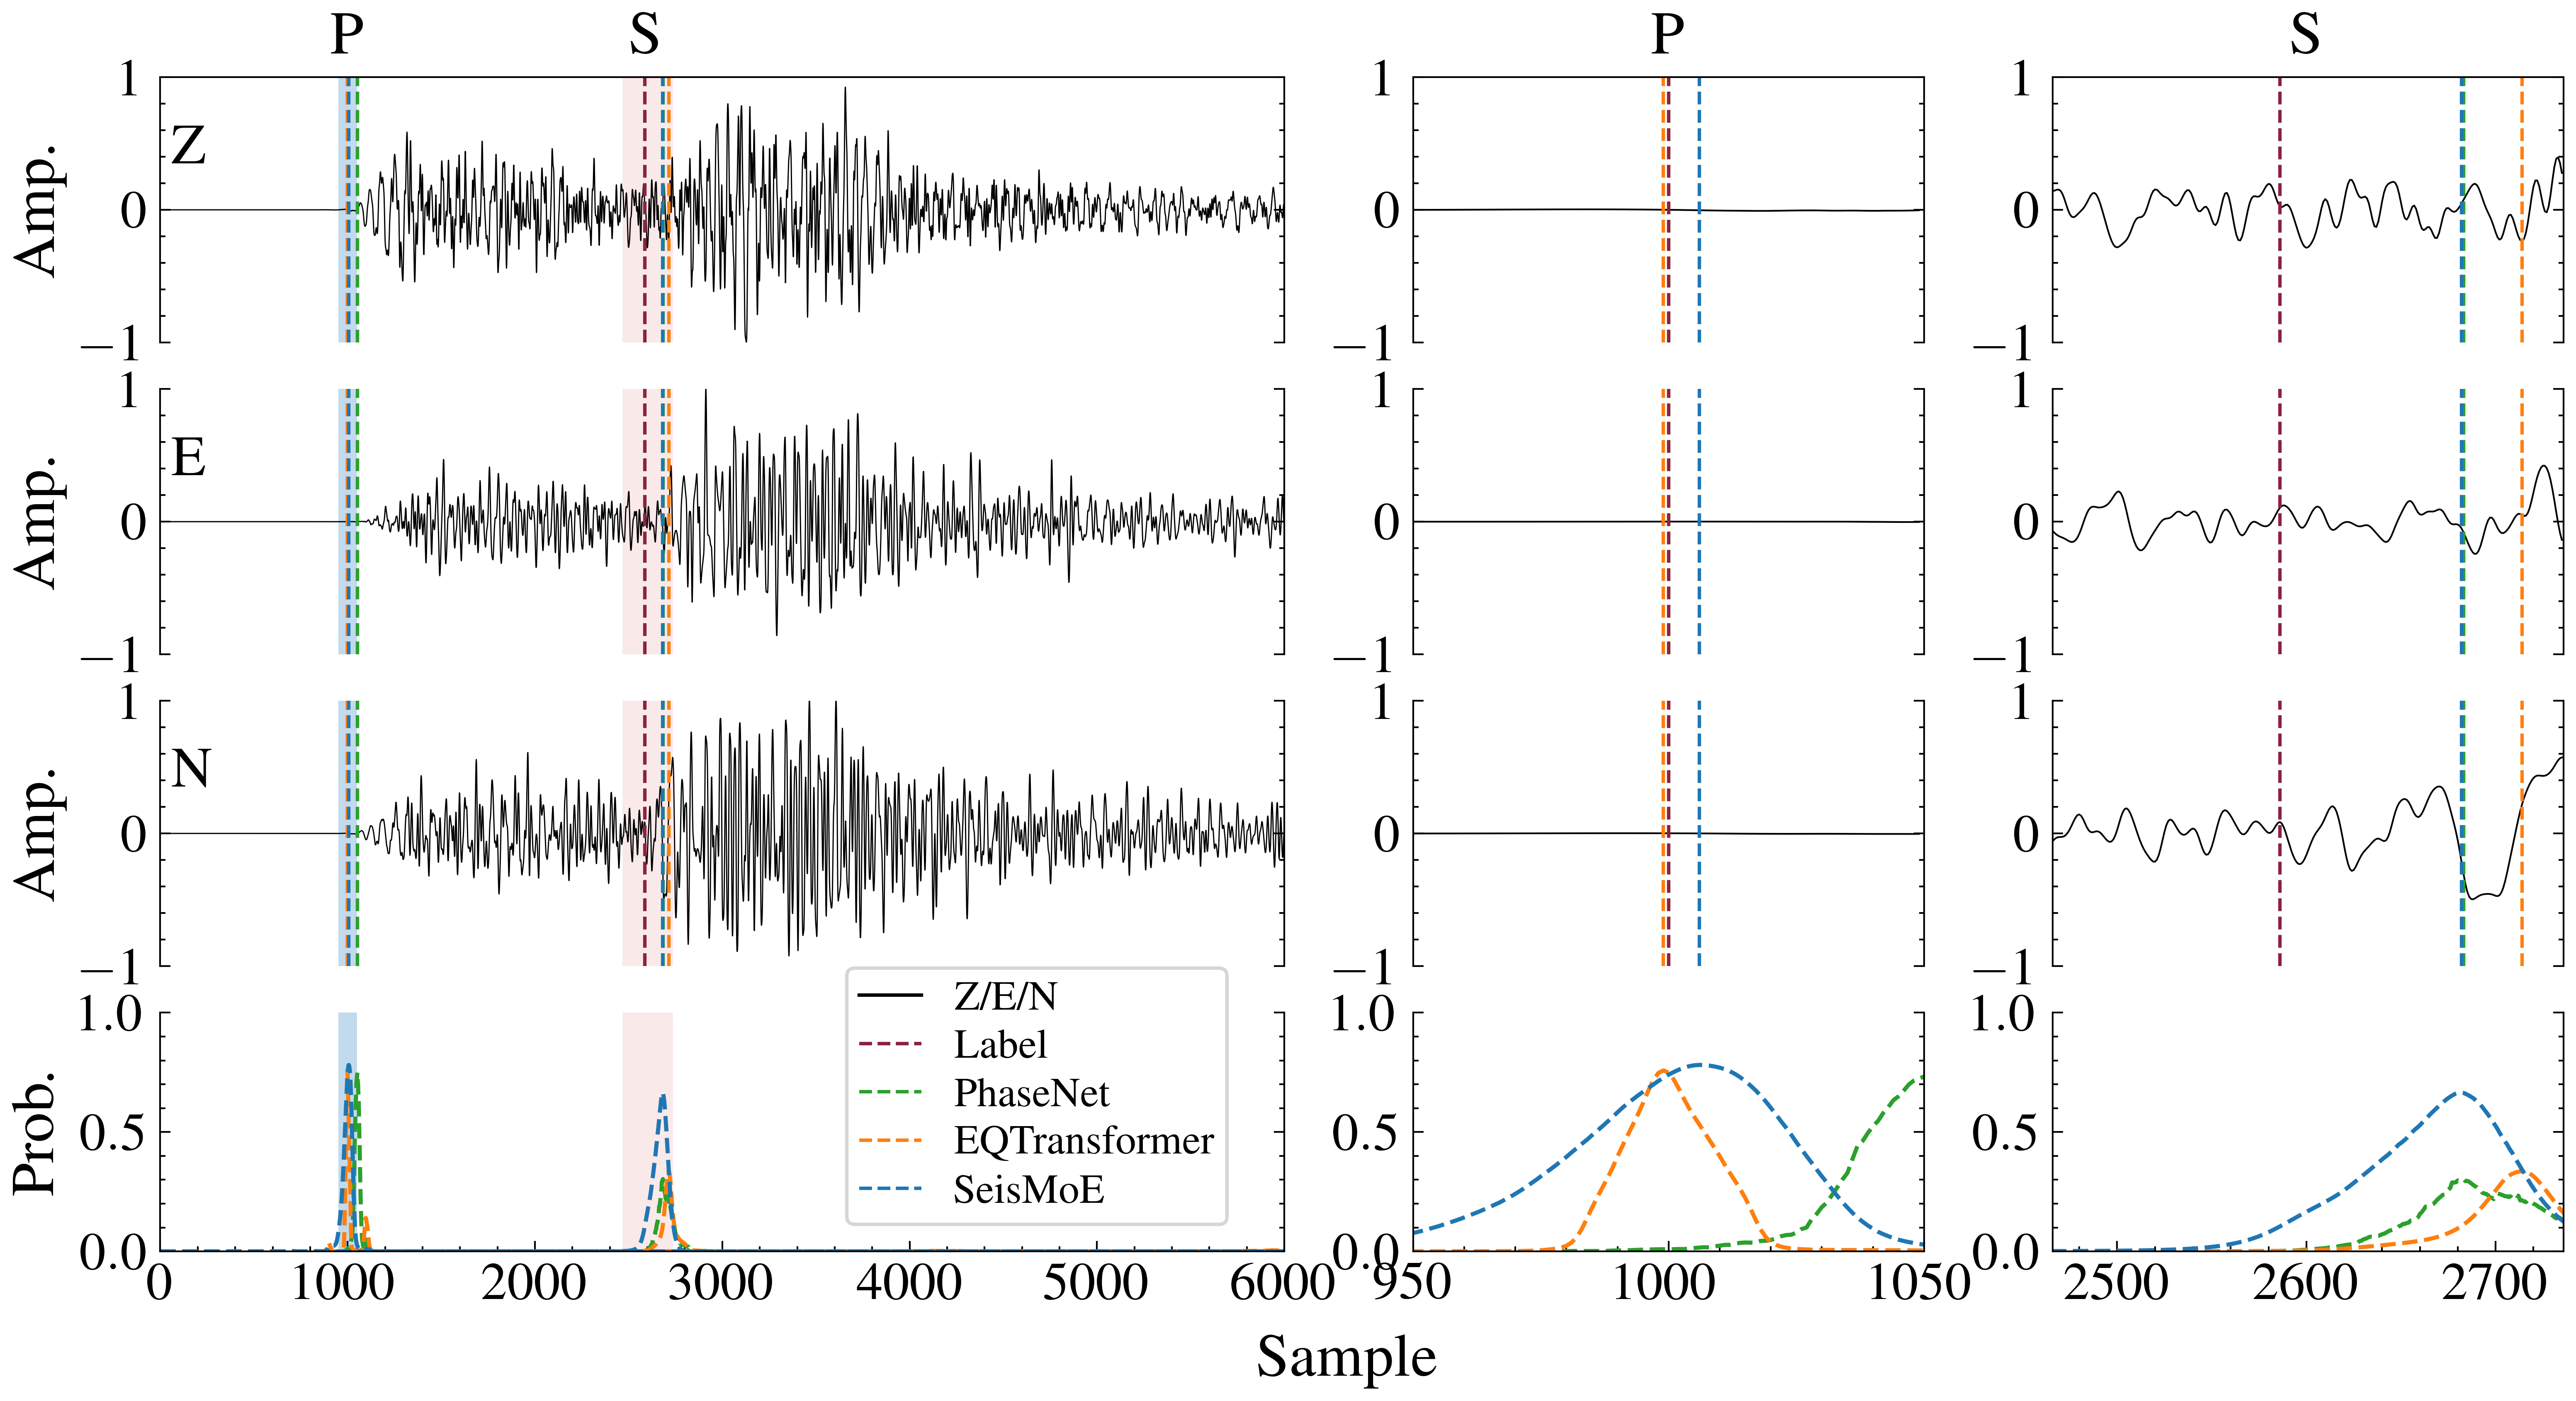

In [ ]:
# trace_name='689168.0903_EV'
trace_name='M23K.TA_20181130172938_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            # store_name='GO01.C_20140403024333_EV_M7.9_SNR_60')
            store_name='M23K.TA_20181130172938_EV_M6.8_SNR103.7')

## GO03.C_20130130201548_EV_M6.8_SNR_104.6

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:901
Moe S index:2053
Moe P confidence:0.8793267011642456
Moe S confidence:0.6191131472587585
eqt P index:899
eqt S index:2072
eqt P confidence:0.9019985198974609
eqt S confidence:0.37677788734436035
phasenet P index:921
phasenet S index:2043
phasenet P confidence:0.5342157483100891
phasenet S confidence:0.3304142653942108


/tmp/ipykernel_1081828/3493167480.py:680: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data = pd.read_csv(cs)


Psample:900
Ssample:2049


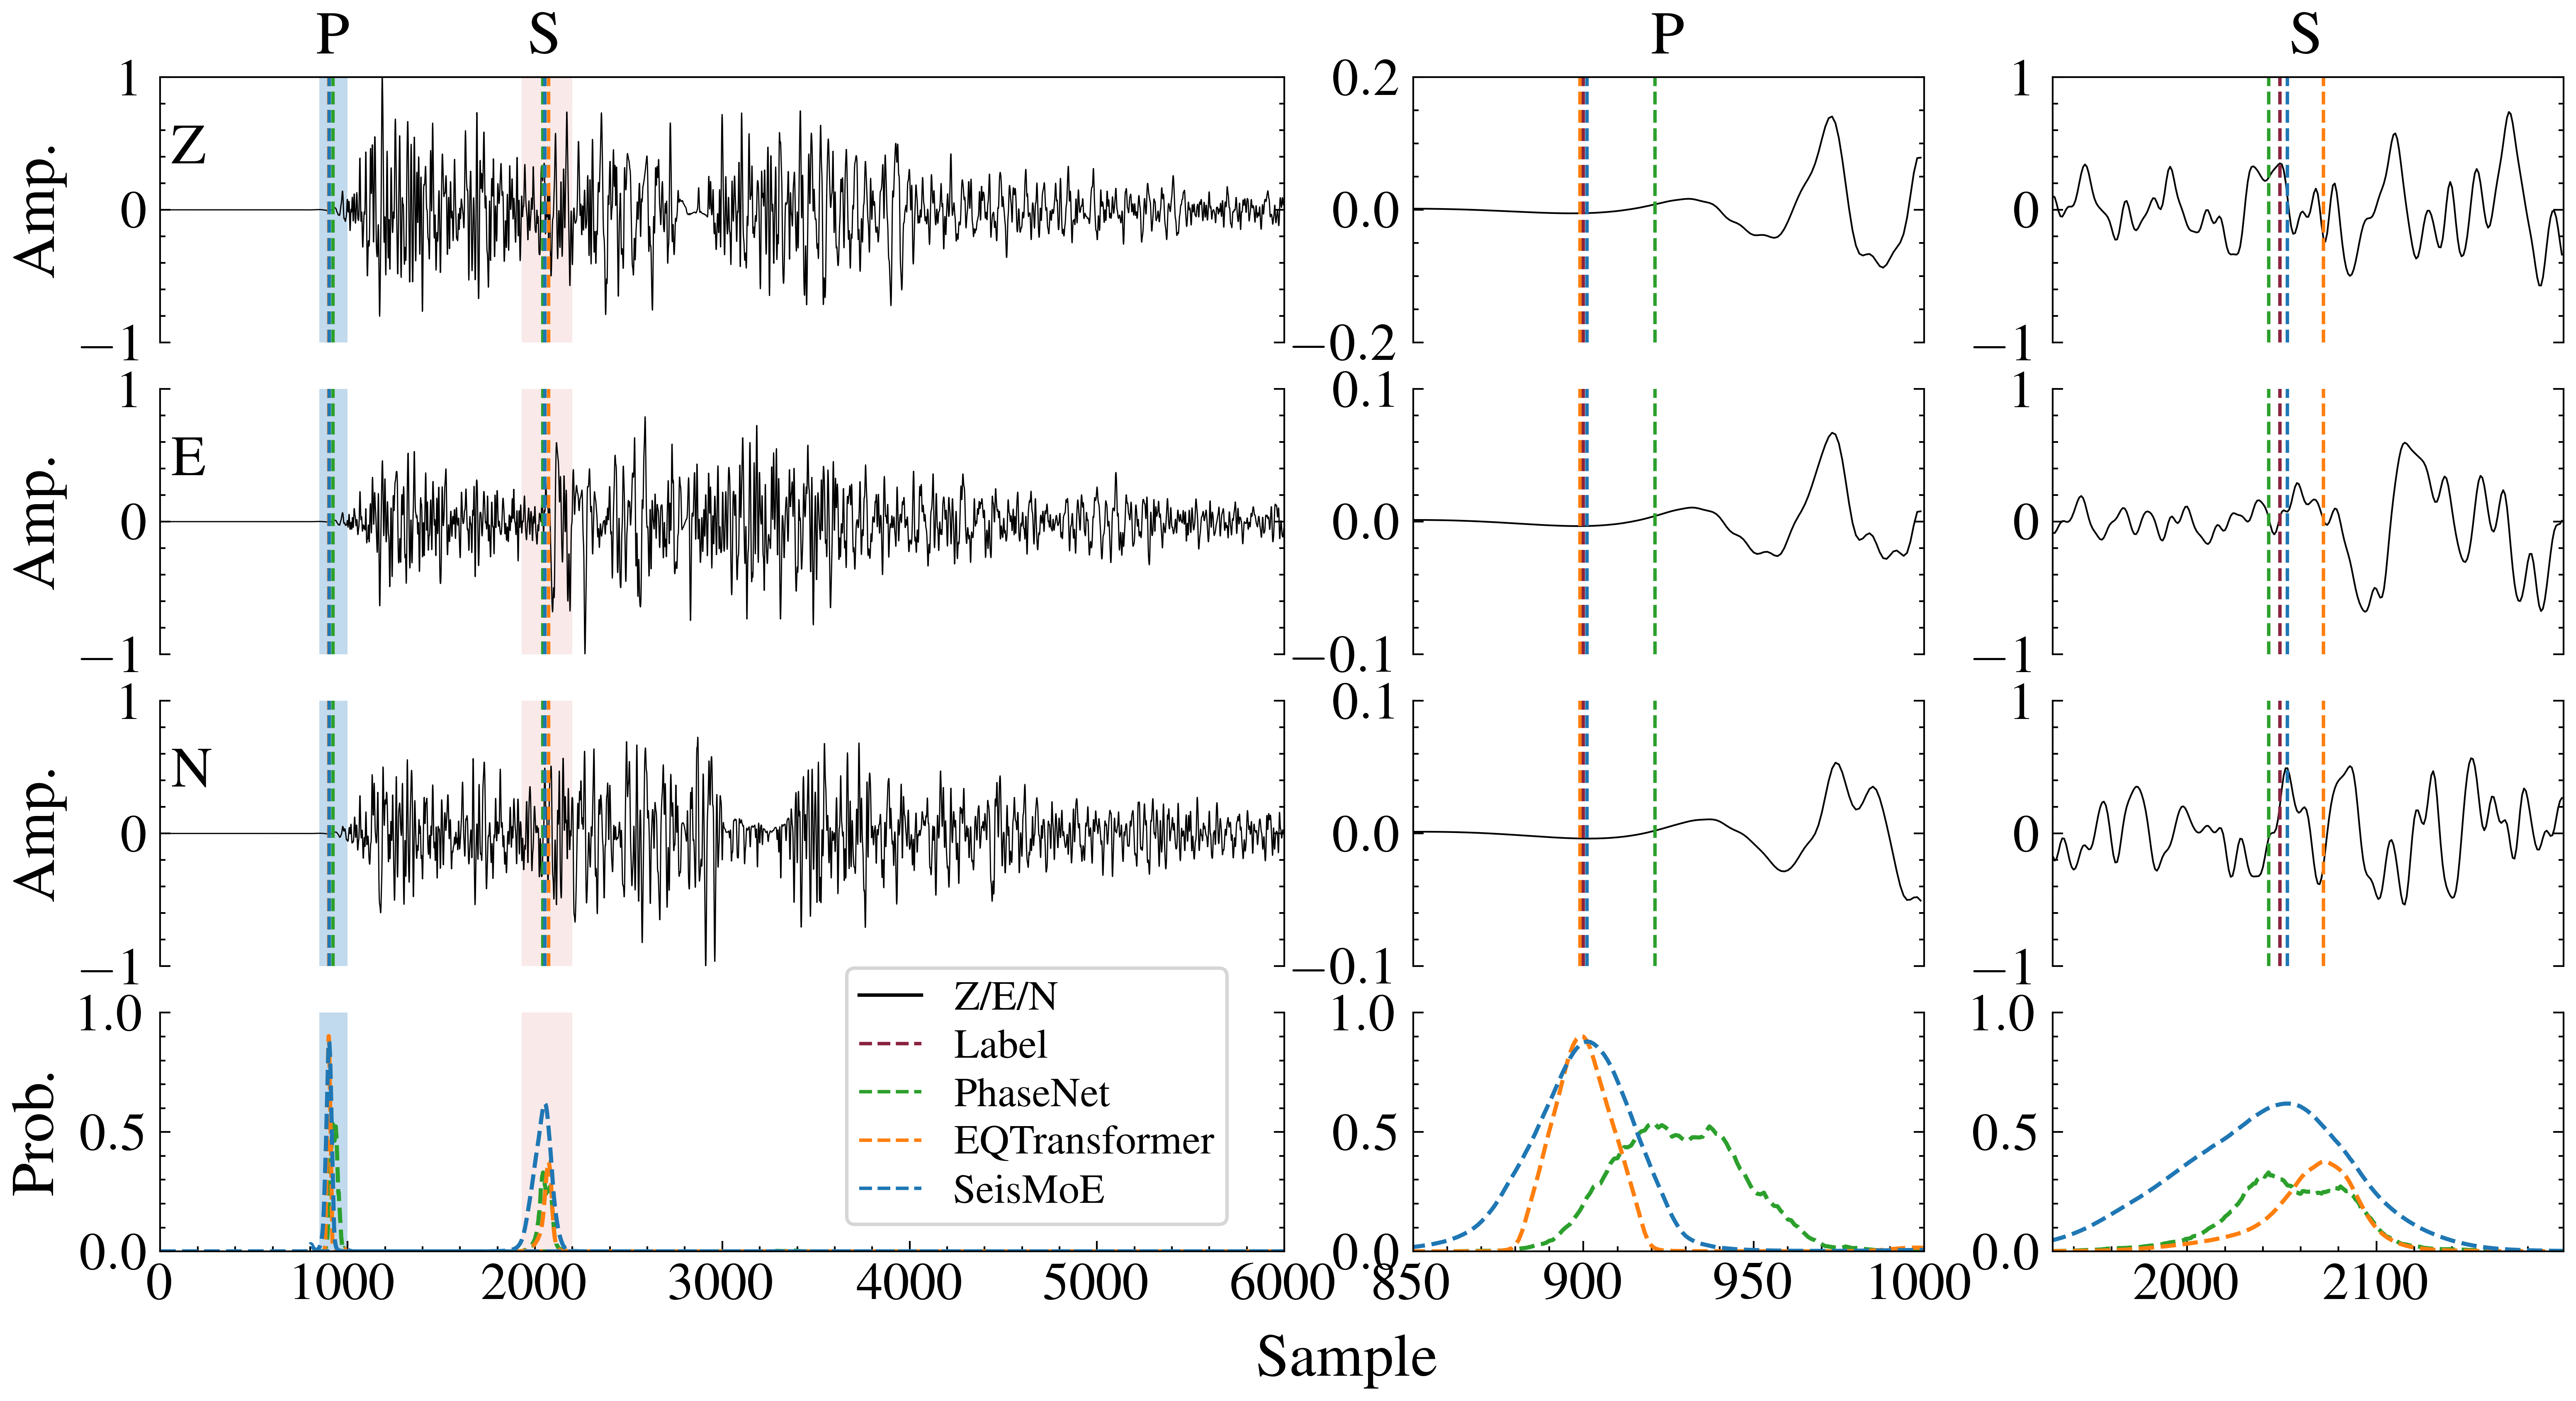

In [16]:
# trace_name='689168.0903_EV'
# trace_name='GO02.C_20130925131520_EV'
trace_name='GO03.C_20130130201548_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            # store_name='GO02.C_20130925131520_EV_M5.3_SNR_71')
            store_name='GO03.C_20130130201548_EV_M6.8_SNR_104.6')

## B004.PB_20140905132114_EV_M0.42_SNR_7.1

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:699
Moe S index:1147
Moe P confidence:0.9491797685623169
Moe S confidence:0.8580253720283508
eqt P index:700
eqt S index:1133
eqt P confidence:0.931993842124939
eqt S confidence:0.7155544757843018
phasenet P index:703
phasenet S index:1141
phasenet P confidence:0.9863052368164062
phasenet S confidence:0.7600612640380859


/tmp/ipykernel_1081828/1577534349.py:680: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data = pd.read_csv(cs)


Psample:700
Ssample:1148


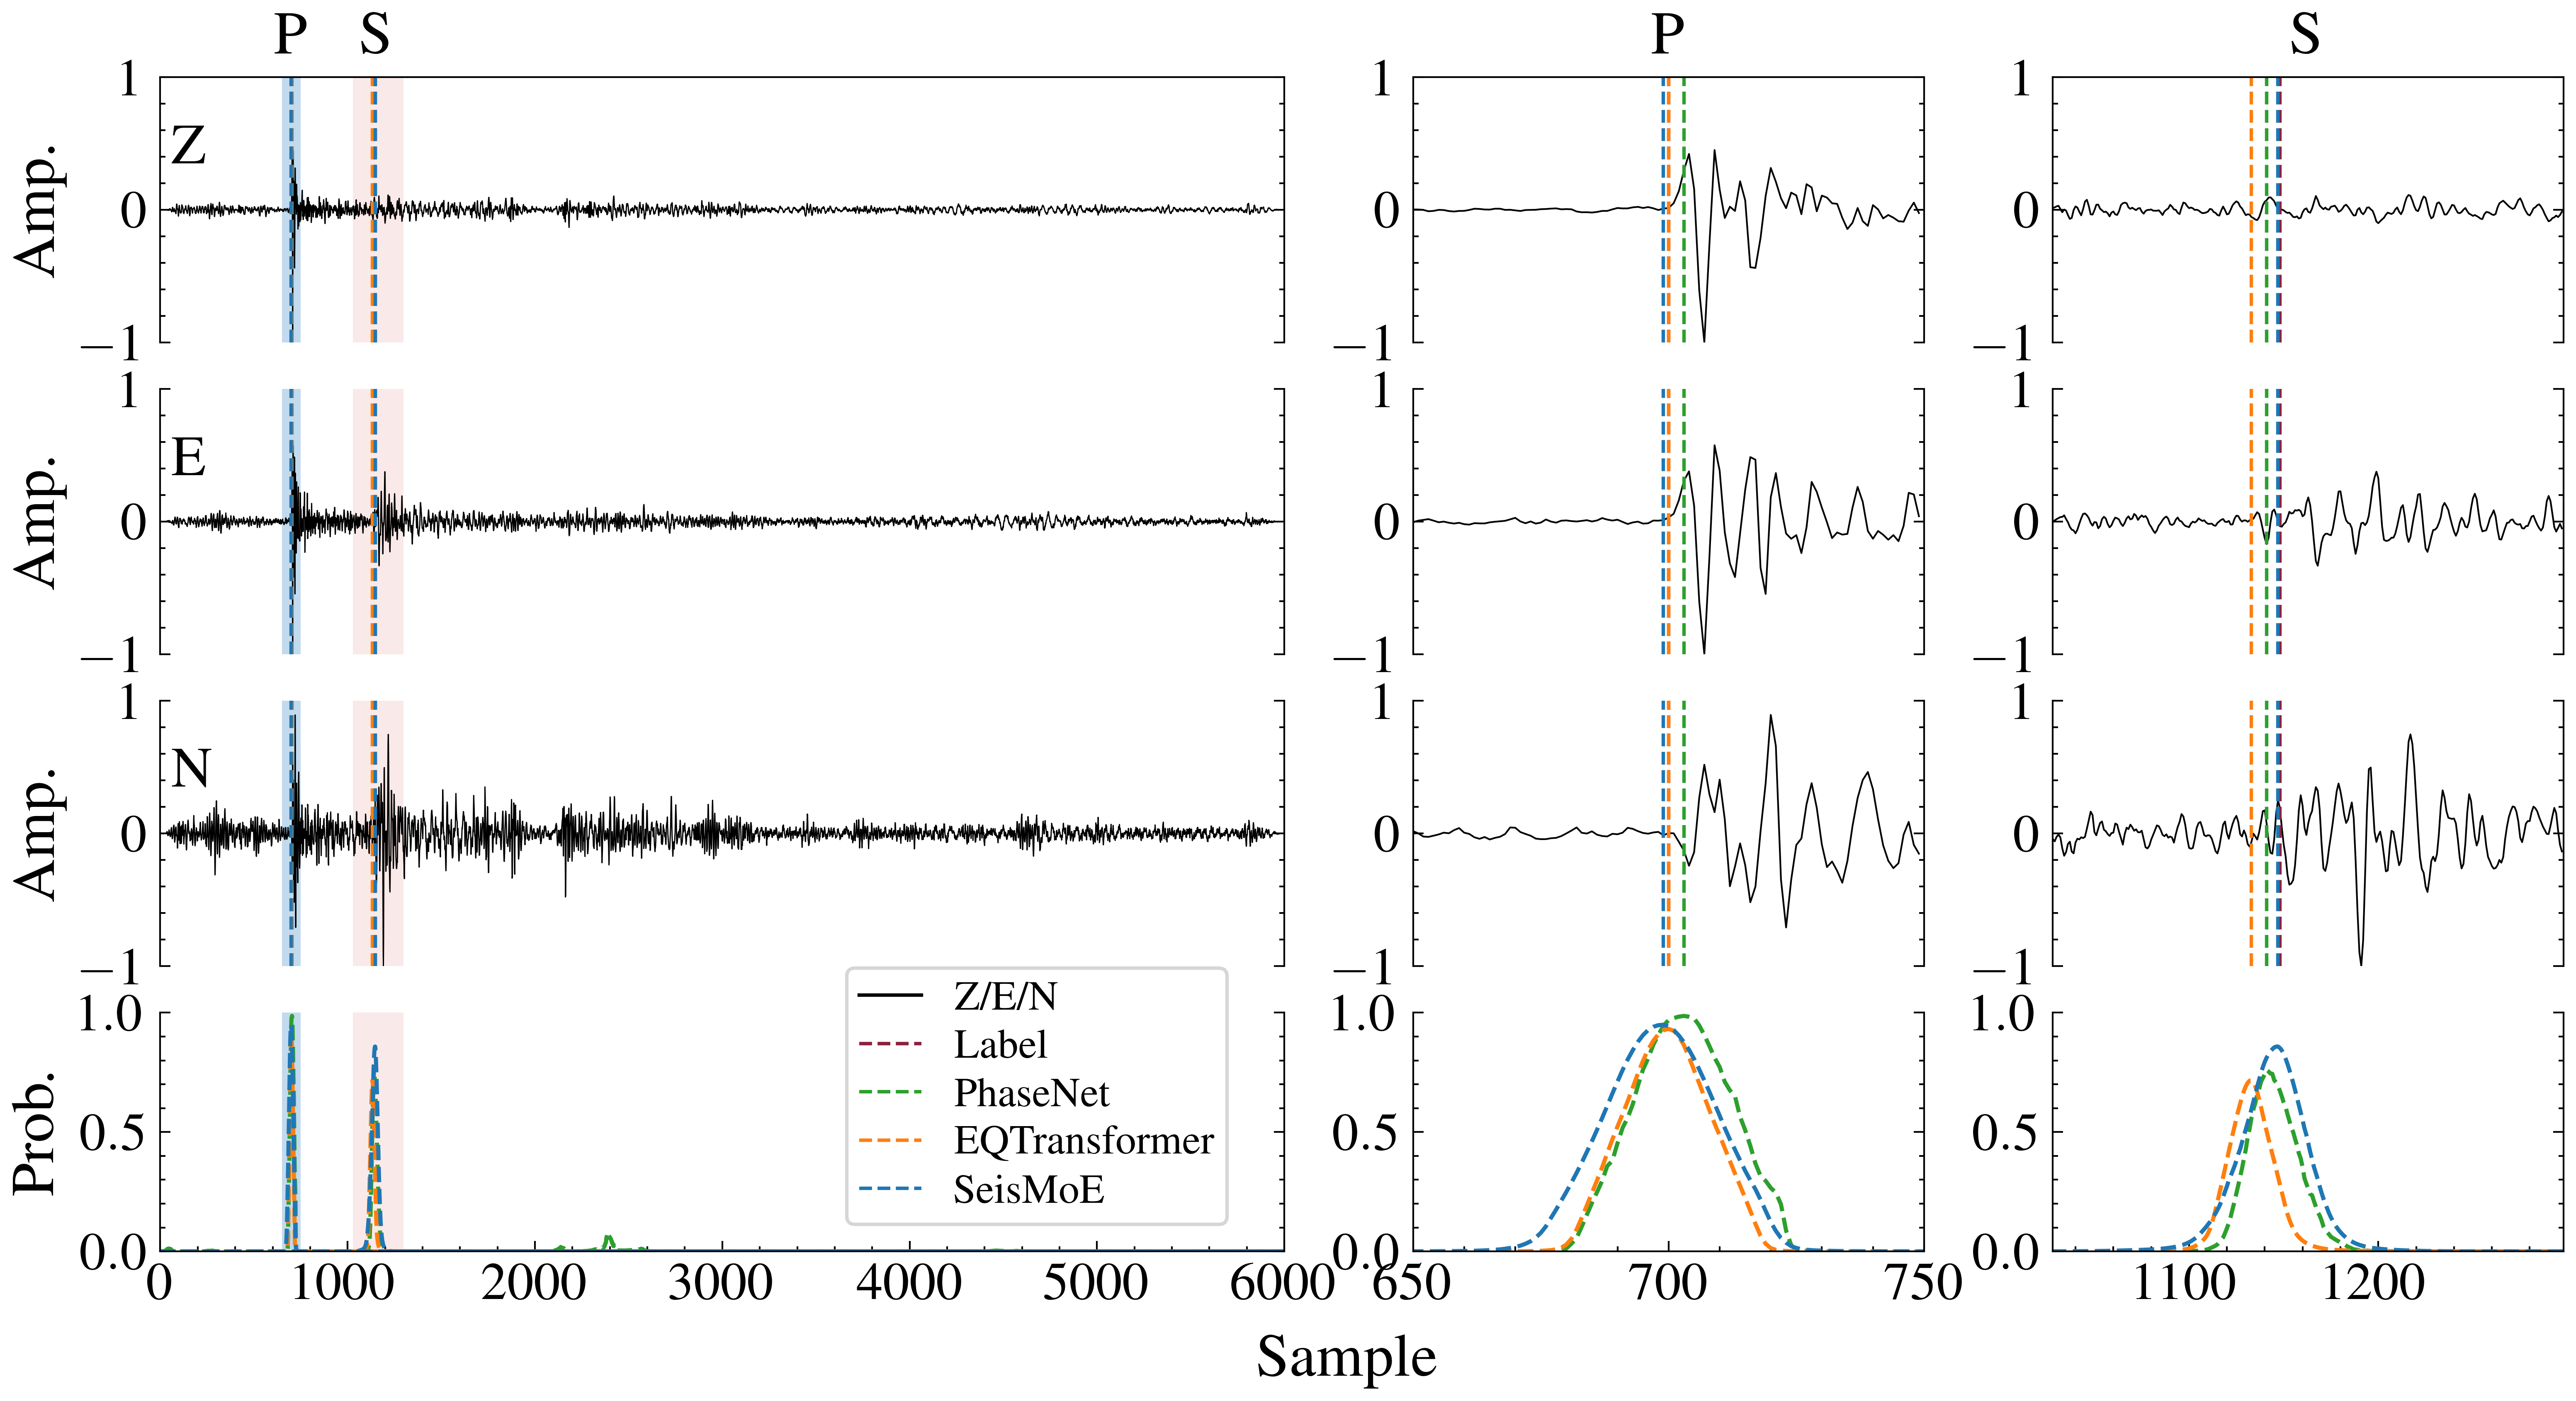

In [6]:
# trace_name='689168.0903_EV'
trace_name='B004.PB_20140905132114_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            store_name='B004.PB_20140905132114_EV_M0.42_SNR_7.1')

## B013.PB_20110710113727_EV_M0.4_SNR_8.2

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:603
Moe S index:907
Moe P confidence:0.949325680732727
Moe S confidence:0.9110392332077026
eqt P index:600
eqt S index:908
eqt P confidence:0.9344328045845032
eqt S confidence:0.8743201494216919
phasenet P index:603
phasenet S index:908
phasenet P confidence:0.9779364466667175
phasenet S confidence:0.9637324810028076


/tmp/ipykernel_1080306/1577534349.py:680: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data = pd.read_csv(cs)


Psample:600
Ssample:905


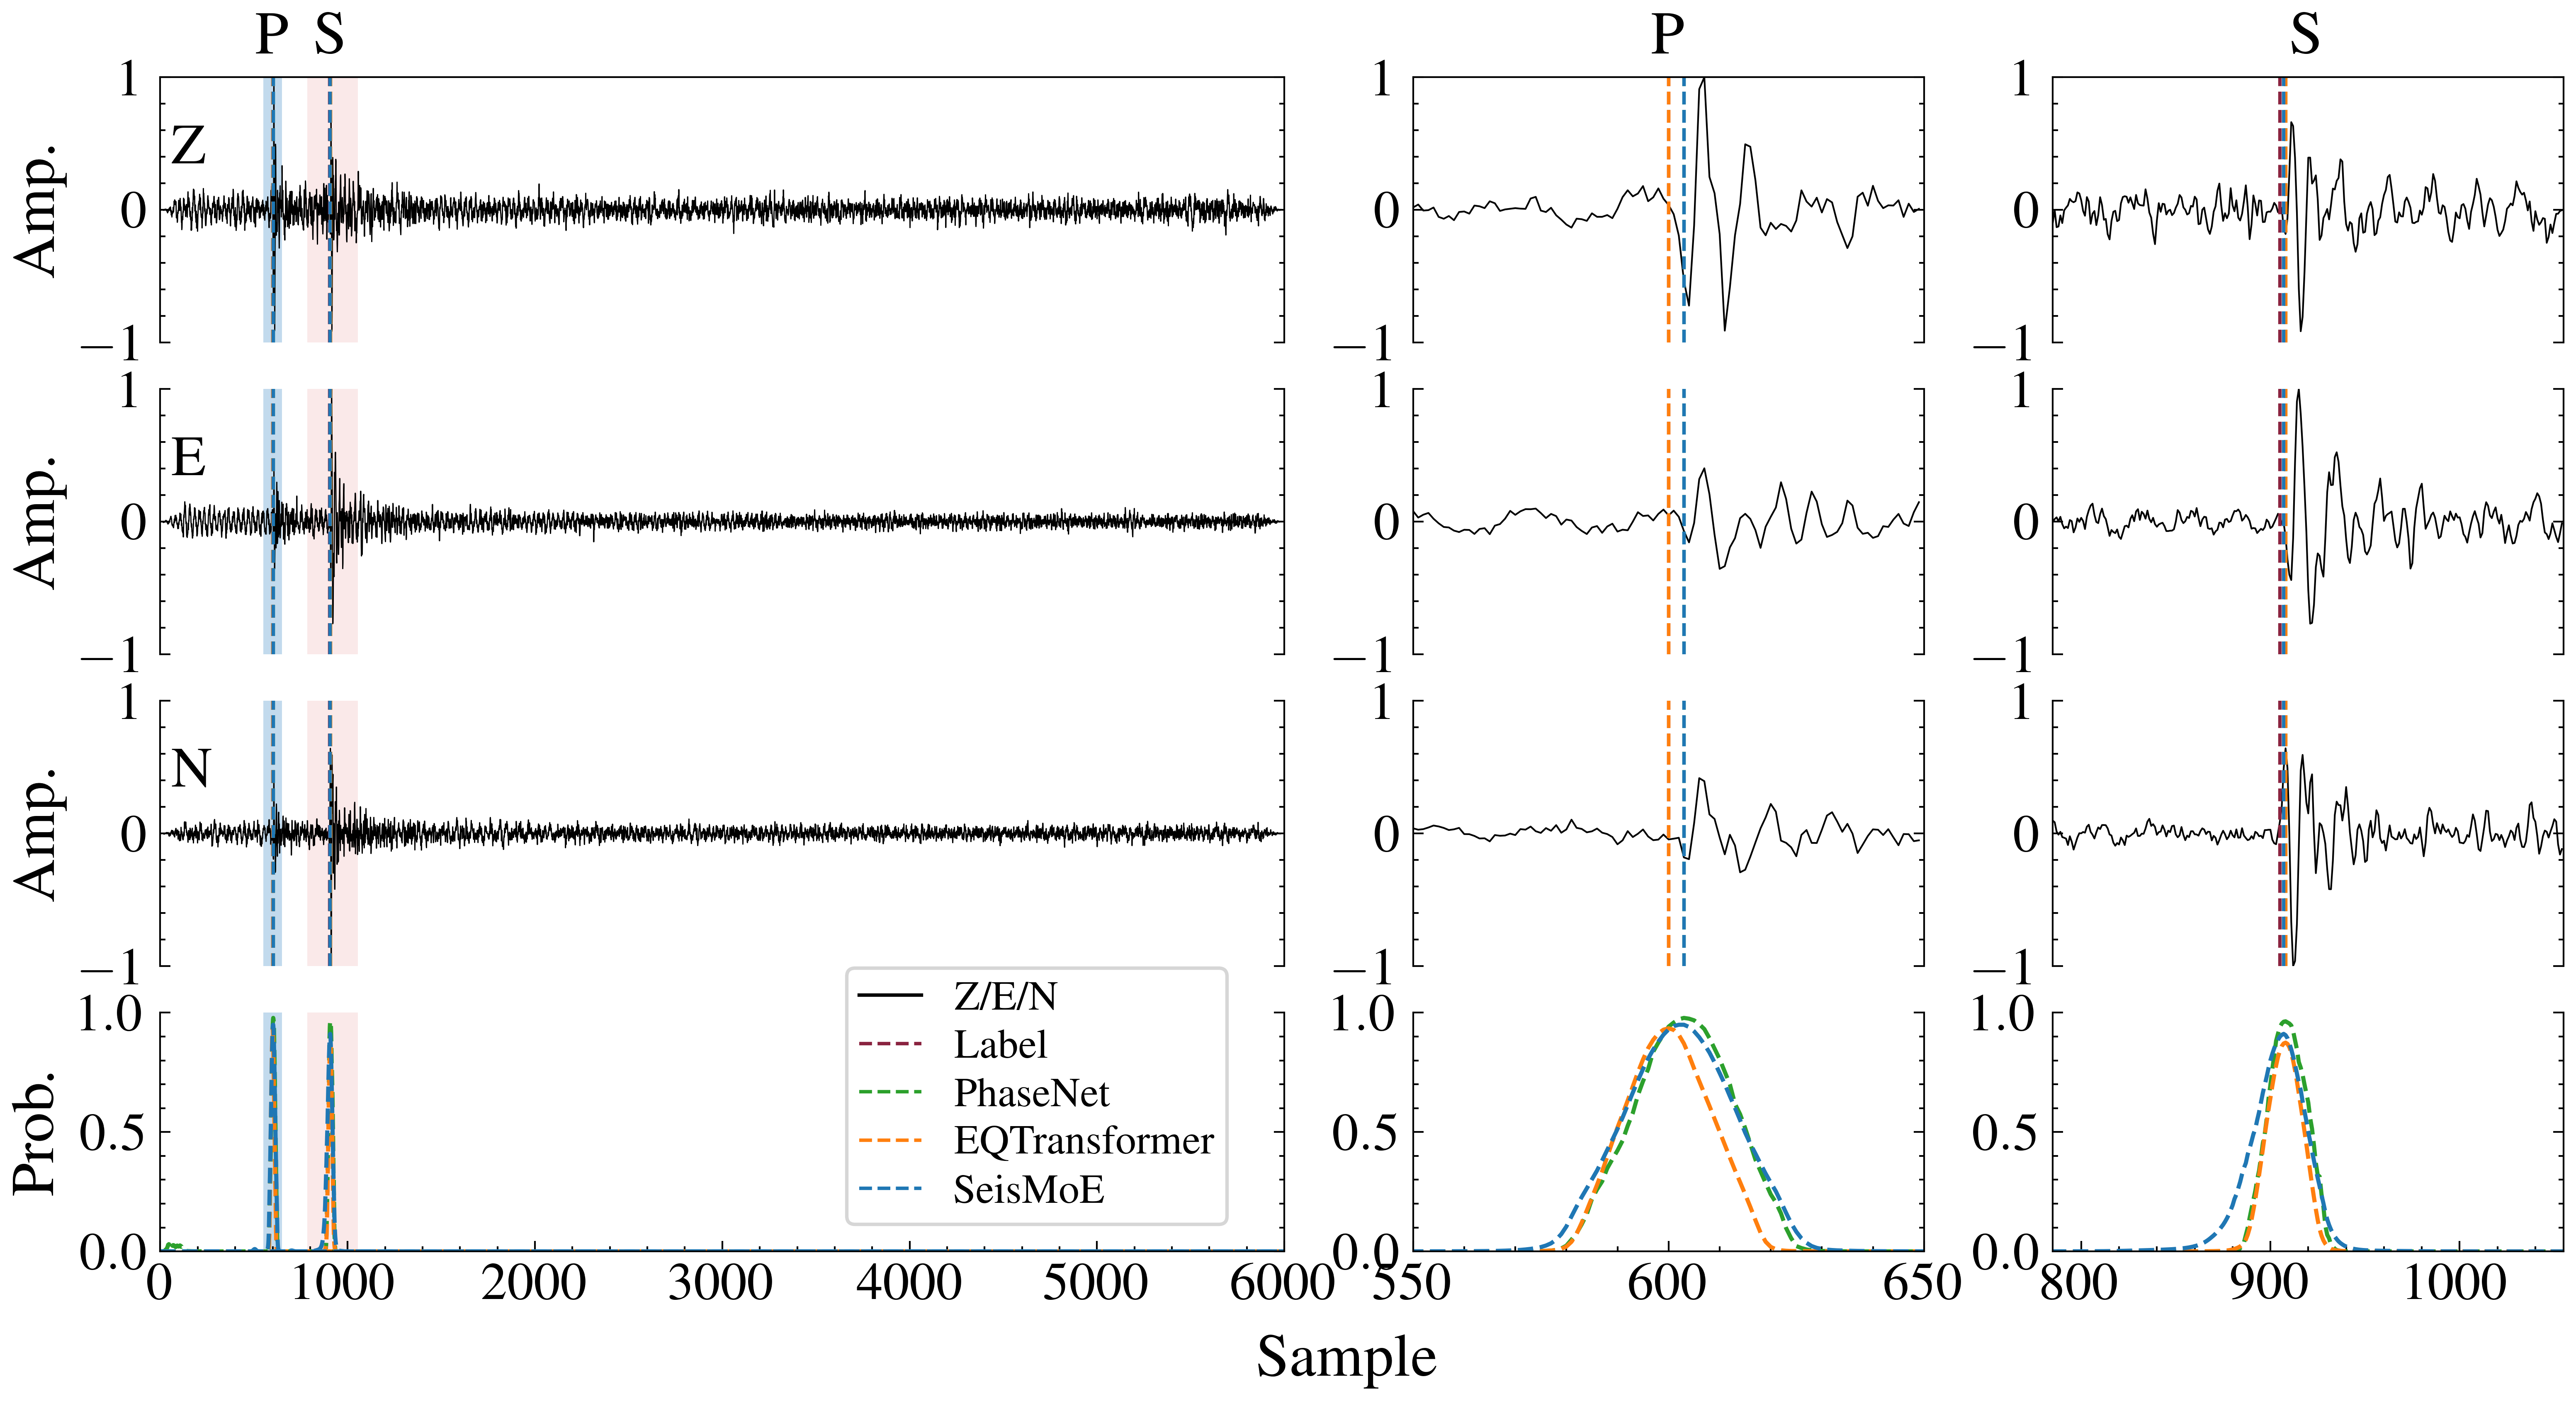

In [ ]:
# trace_name='689168.0903_EV'
trace_name='B013.PB_20110710113727_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            store_name='B013.PB_20110710113727_EV_M0.4_SNR_8.2')

## BJOB.NC_20110206113213_EV_M1.1_SNR_5.3

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:798
Moe S index:1001
Moe P confidence:0.9636437892913818
Moe S confidence:0.9206196665763855
eqt P index:800
eqt S index:997
eqt P confidence:0.9324048757553101
eqt S confidence:0.840563178062439
phasenet P index:802
phasenet S index:1004
phasenet P confidence:0.9501829147338867
phasenet S confidence:0.8761855363845825


/tmp/ipykernel_1081828/1577534349.py:680: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data = pd.read_csv(cs)


Psample:800
Ssample:1000


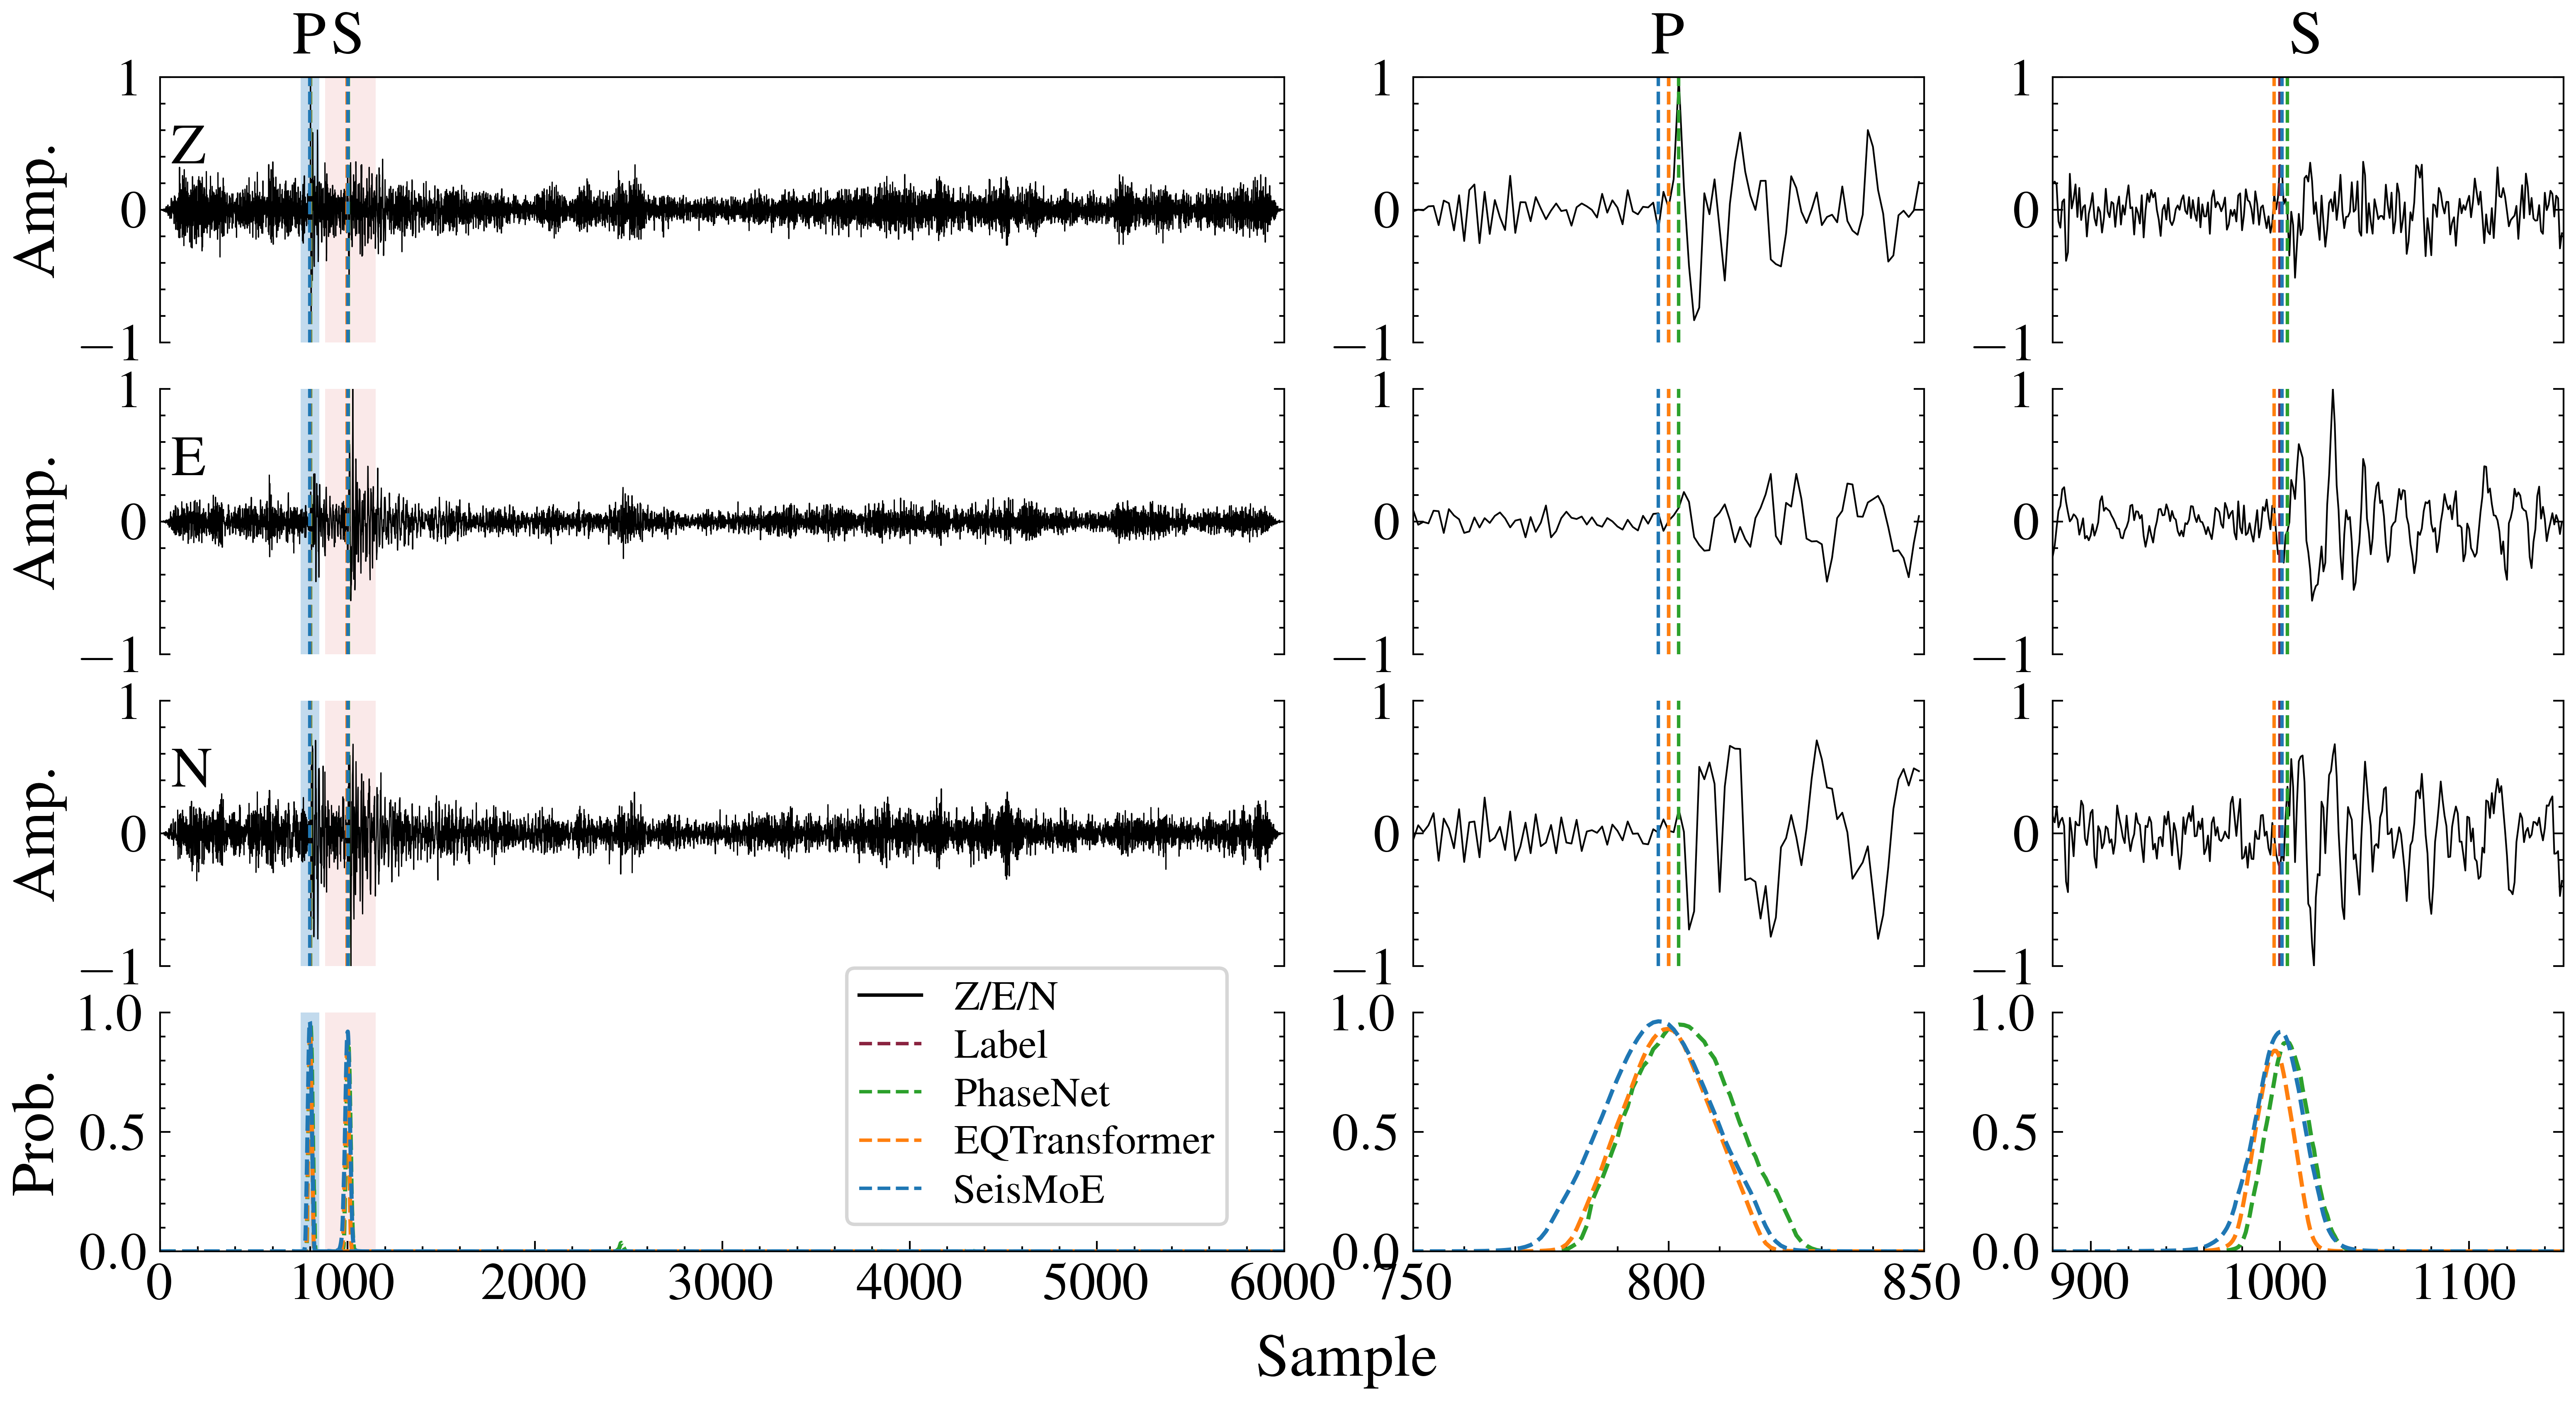

In [7]:
# trace_name='689168.0903_EV'
trace_name='BJOB.NC_20110206113213_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            store_name='BJOB.NC_20110206113213_EV_M1.1_SNR_5.3')

## CVS.BK_20130831203928_EV_M1.4_SNR5.3

In [ ]:

trace_name='CVS.BK_20130831203928_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/STEAD',
            store_name='CVS.BK_20130831203928_EV_M1.4_SNR5.3')

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:800
Moe S index:1501
Moe P confidence:0.8029342889785767
Moe S confidence:0.4842498004436493
eqt P index:800
eqt S index:1529
eqt P confidence:0.9029090404510498
eqt S confidence:0.5249976515769958
phasenet P index:805
phasenet S index:1537
phasenet P confidence:0.874652624130249
phasenet S confidence:0.6856773495674133


# tfgsdr